In [33]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
import random

from torchvision import transforms
from sklearn.model_selection import train_test_split

import torch
import cv2
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder

## Подготовка данных

In [20]:
train_df = pd.read_csv("ML9_dataset/Train.csv")
test_df = pd.read_csv("ML9_dataset/Test.csv")
sample = pd.read_csv("ML9_dataset/SampleSubmission.csv")

In [21]:
ran_rows = random.sample(range(0, train_df.shape[0]), 10)

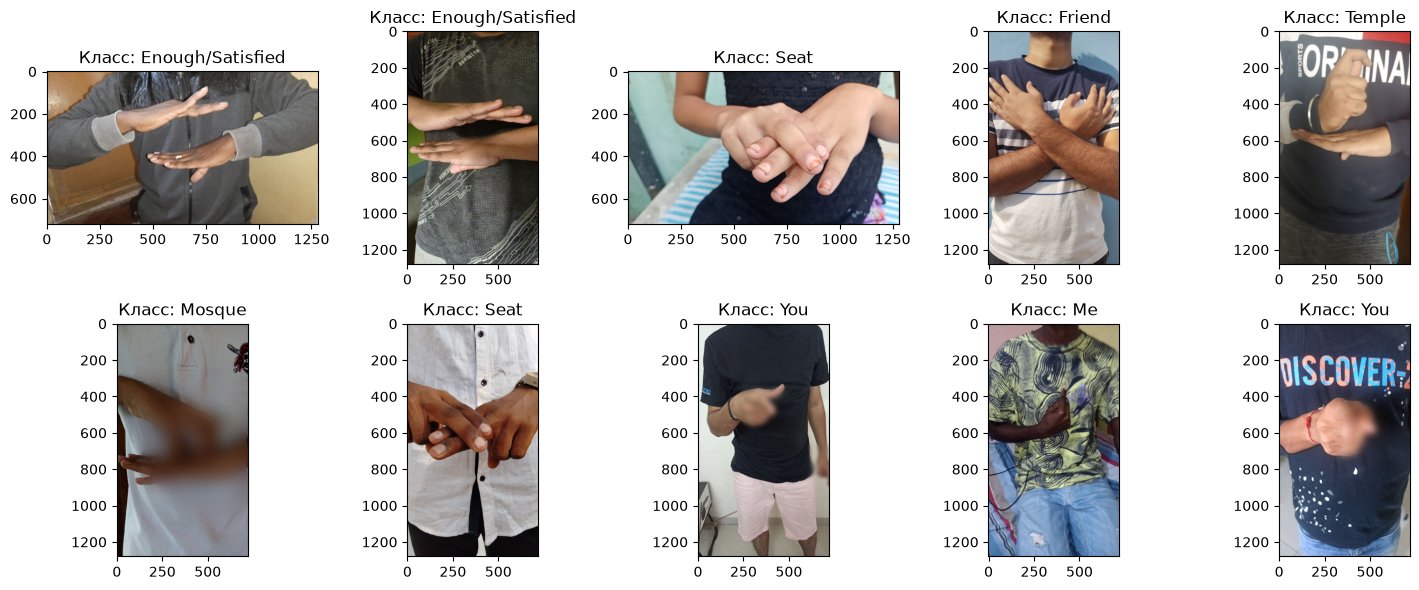

In [4]:
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
ax = ax.flatten()   
sizze = list()
for i, (ind, row) in enumerate(train_df.iloc[ran_rows].iterrows()):
    img_name = row['img_IDS']
    target = row['Label']
    
    img_path = os.path.join('ML9_dataset/Images/', img_name + '.jpg')

    if os.path.exists(img_path):
        img = Image.open(img_path)
        sizze.append(img.size)
        ax[i].imshow(img)
        ax[i].set_title(f"Класс: {target}")

plt.tight_layout()
plt.show()

In [5]:
sizze

[(1280, 720),
 (720, 1280),
 (1280, 720),
 (720, 1280),
 (720, 1280),
 (720, 1280),
 (720, 1280),
 (720, 1280),
 (720, 1280),
 (720, 1280)]

Тут я заметила, что изображения слишком большие, поэтому ниже применила Resize.

In [30]:
train_transform = transforms.Compose([
    transforms.Resize(256), # маленькая сторона 256
    # transforms.RandomCrop(size=224, padding=4), # обрезка размера 224
    transforms.RandomRotation(degrees=(-10, 10)), # поворот
    transforms.ColorJitter(brightness=0.2, contrast=0.2), # ±20% яркость и контраст
    transforms.RandomPerspective(distortion_scale=0.1, p=0.1, fill=(0,0,0)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

Это аугментации, те расширение данных за счет самих данных, но без использования лишней памяти.
\
Я использовала:
- обрезку, чтобы жест не всегда был в центре
- поворот, по горизонтали, но не сильный (от -10 до 10 градусов), чтобы не менялась суть жестов
- изменение свойств, таких как яркость и контростность
- перспеутива, чтобы жесты были под углом в 10% случаев

Все остальные преобразования нужны для дальнейшей корректной обработки данных.

In [22]:
train_data, val_data = train_test_split(train_df, test_size=0.33, stratify=train_df['Label']) # stratify - сохранение пропорций каждого класса    

In [8]:
# !find ML9_dataset/Images -name '*:Zone.Identifier' -delete

Я удалила все файлы, которые указывали на то, что файл скачан из интернета

### Создание своего датасета

In [27]:
class MyImageDataset(Dataset):
    def __init__(self, labels_df, img_dir, transform=None):
        self.img_labels = labels_df
        self.img_dir = img_dir
        self.transform = transform
 
    def __len__(self):
        return len(self.img_labels)
 
    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, self.img_labels.iloc[idx, 0] + '.jpg')
        image = cv2.imread(img_path)
        if image is None:
            raise FileNotFoundError(f"Не найдено: {img_path}")

        img = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        img = Image.fromarray(img) # из numpy в PIL
        
        target = self.img_labels.iloc[idx, 1]
        if self.transform:
            img = self.transform(img)
        else:
            img = torch.from_numpy(np.array(img)).permute(2, 0, 1).float() / 255.0
        return img, target

In [23]:
le = LabelEncoder()
train_data['Label'] = le.fit_transform(train_data['Label'])
val_data['Label'] = le.transform(val_data['Label'])

In [28]:
# le.classes_
class_to_idx = {cls: i for i, cls in enumerate(le.classes_)}
print(class_to_idx)

{'Church': 0, 'Enough/Satisfied': 1, 'Friend': 2, 'Love': 3, 'Me': 4, 'Mosque': 5, 'Seat': 6, 'Temple': 7, 'You': 8}


In [35]:
train_dataset = MyImageDataset(train_data, img_dir='ML9_dataset/Images/', transform=train_transform)
val_dataset = MyImageDataset(val_data, img_dir='ML9_dataset/Images/', transform=val_transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

In [38]:
images, labels = next(iter(train_loader))

print("Тип images:", type(images))
print("Тип labels:", type(labels))
print("Форма images:", images.shape)   # например torch.Size([32, 3, 224, 224])
print("Форма labels:", labels.shape)   # torch.Size([32])
print("dtype images:", images.dtype)
print("dtype labels:", labels.dtype)
print("Первые 10 меток:", labels[:10])

RuntimeError: stack expects each tensor to be equal size, but got [3, 256, 455] at entry 0 and [3, 455, 256] at entry 3

!git add ml9.ipynb
!git commit -m "Последняя подготовка данных"
!git push origin develop

!git add ML9_dataset/Images/
!git commit -m "Данные"
!git push origin develop